In [70]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from itertools import product

import sys
from pathlib import Path

In [285]:
#TODO row protection by lambda in row_threshold?
def adaptive_prune_to_complete(
    data: pd.DataFrame,
    max_iter:int = 100,
    shrink_coeff:float = 10,
    verbose: bool = False
):
    n_rows, n_cols = data.shape
    X = data.copy()

    # container for benchmarking info
    # i: iteration no
    # no_prunned_cols: no of prunned columns
    # no_prunned_rows: no of prunned rows
    # eff_lr: effective learning rate
    iteration_info = []
    
    # iteration count
    i = 1
    while(i <= max_iter):
        if verbose:
                print(
                    f"i={i}, shape={X.shape},\n"
                )
        
        if n_rows == 0 or n_cols == 0:
            return None, None
        
        ### remove columns ###

        # pick threshold
        # fraction of elements in the least populated row
        col_avail = X.notna().sum(axis=0)
        min_fraction_col = (col_avail/n_rows).min()
        # fraction of missing + shrunk learning_rate
        col_threshold = min_fraction_col + (1 - min_fraction_col)/(shrink_coeff * i)

        if verbose:
            print(
                f"A column with min values has {col_avail.min():.3f} entries.\n"
                f"Threshold of column elimination is {col_threshold:.3f}, it eliminates columns with less than {int(col_threshold * n_rows)} entries."
            )
        
        # save the number of old columns
        n_cols_old = X.shape[1]
        
        # prune columns
        X = X.loc[:, col_avail >= col_threshold * n_rows]
        
        # update column count
        n_cols = X.shape[1]
        if n_cols == 0: 
            return None, None

        ### remove rows ###
        
        # pick threshold
        # fraction of elements in the least populated row
        row_avail = X.notna().sum(axis=1)
        min_fraction_row = (row_avail/n_cols).min()
        # fraction of missing + shrunk learning_rate
        row_threshold = min_fraction_row + (1 - min_fraction_row)/(shrink_coeff * i)

        if verbose:
            print(
                f"A row with min values has {row_avail.min():.3f} entries.\n"
                f"Threshold of row elimination is {row_threshold:.3f}, it eliminates rows with less than {int(row_threshold * n_cols)} entries."
            )

        n_rows_old = X.shape[0]
        
        # prune rows
        X = X.loc[row_avail >= row_threshold * n_cols, :]

        # update row count
        n_rows = X.shape[0]
        if n_rows == 0:
            return None, None

        missing = X.isna().sum().sum()
        total = X.shape[0] * X.shape[1]

        if verbose:
            print(
                f"missing={missing}/{total}\n"
            )

        iteration_info.append({
            "i": i,
            "no_prunned_rows": n_rows_old - n_rows,
            "no_prunned_cols": n_cols_old - n_cols,
            "eff_lr": 1/(shrink_coeff * i)
        })

        if missing == 0: break
        
        i += 1

    iteration_info = pd.DataFrame(iteration_info)
    if i <= max_iter: return X, iteration_info
    else:
        print(f"{max_iter} iterations reached without convergence.")

In [318]:
def experiment(n_complete, d_complete, 
               n_big, d_big,
               missingness,
               C_list
              ):
    # generate complete matrix to be planted
    complete = rng.standard_normal(size=(n_complete, d_complete))

    # generate big encompassing matrix
    big = rng.standard_normal((n_big, d_big))

    if big.size - complete.size < big.size * missingness:
        print("Experiment not possible with given parameters")
        return None

    # plant a complete matrix
    rows = np.sort(rng.choice(n_big, size=n_complete, replace=False))
    cols = np.sort(rng.choice(d_big, size=d_complete, replace=False))
        
    big[np.ix_(rows,cols)] = complete

    # apply missingness
    available_mask = extract_mask(big, rows, cols)
    apply_missingness(big, available_mask, missingness)
        
    df = pd.DataFrame(big)

    # recovered matrices
    results = {}
    # iteration information
    iter_info = {}

    for C in C_list:
        # found submatrix, iteration information
        results[C], iter_info[C] = adaptive_prune_to_complete(df, max_iter=1000, shrink_coeff=C, verbose=False)

        # check if a found matrix is indeed complete
        assert results[C] is None or results[C].isna().sum().sum() == 0, f"{C}"

    results = pd.DataFrame([{
        'C':C, 
        'found_area': matrix.size, 
        'row_cnt': matrix.shape[0],
        'col_cnt': matrix.shape[1]}
            for C, matrix in results.items() if matrix is not None])

    iter_info = pd.DataFrame([{
        'C': C, 
        'no_iter': ii["i"].max()} 
            for C, ii in iter_info.items() if ii is not None])

    results = pd.merge(results, iter_info, on='C', how='left')
    
    #results.sort_values(by=['found_area', 'C', 'row_cnt', 'col_cnt'], ascending=[False, True, False, False], inplace = True)
    
    return results

In [313]:
def extract_mask(matrix, excluded_rows, excluded_cols):
    excluded_mask = np.zeros(matrix.shape, dtype=bool)
    excluded_mask[np.ix_(excluded_rows, excluded_cols)] = True
    return ~excluded_mask

In [314]:
def apply_missingness(matrix, available_mask, missingness):
    # assumes applying missingness is possible
    no_missing = int(round(missingness * matrix.size))
    available_idx = np.flatnonzero(available_mask)

    missing_idx = rng.choice(available_idx, size = no_missing, replace = False)
    matrix.flat[missing_idx] = np.nan

In [150]:
rng = np.random.default_rng()

In [329]:
#TODO polish fixes
#TODO loop over cross product of dimensions
#TODO add pareto frontier solutions to the resulting DF
#TODO add timing on each result in experiment

# parameters to search through
#shs = np.arange(1, 10, 1)
shs = np.hstack((np.arange(1, 10), np.arange(10, 100, 10), np.arange(100, 300, 20)))

# no of dimensions to test
D = 100

low_complete_data_points = 5
high_complete_data_points = 1500
no_complete_data_points = np.linspace(low_complete_data_points, high_complete_data_points, D).round().astype(int)

low_complete_variables = 5
high_complete_variables = 700
no_complete_variables = np.linspace(low_complete_variables, high_complete_variables, D).round().astype(int)

low_big_data_points = 10
high_big_data_points = 2000
no_big_data_points = np.linspace(low_big_data_points, high_big_data_points, D).round().astype(int)

low_big_variables = 7
high_big_variables = 1000
no_big_variables = np.linspace(low_big_variables, high_big_variables, D).round().astype(int)

# missingness to test
missingness = [0.3, 0.5, 0.7, 0.9]

results = []

T = 100
for d in range(D):
    big_area = no_big_data_points[d] * no_big_variables[d]
    planted_area = no_complete_data_points[d] * no_complete_variables[d]
    for m in missingness:
        for t in range(T):
            matrices = experiment(no_complete_data_points[d], no_complete_variables[d], 
                                  no_big_data_points[d], no_big_variables[d], 
                                  m,
                                  shs)
            # experiment was not possible with given dimensions and missingness
            if matrices is None:
                continue
            # matrix with largest area and largest row count
            matrices.sort_values(by=['found_area', 'row_cnt', 'col_cnt', 'C'], ascending=[False, False, False, True], inplace = True)
            best_found_matrix = matrices.iloc[0]
            best_found_area = best_found_matrix['found_area']
            
            results.append({
                "big_area": big_area,
                "big_rows": no_big_data_points[d],
                "big_cols": no_big_variables[d],
                "planted_area": planted_area,
                "pa_rows": no_complete_data_points[d],
                "pa_cols": no_complete_variables[d],
                "missing": m,
                "largest_area": best_found_area,
                "la_rows": best_found_matrix['row_cnt'],
                "la_cols": best_found_matrix['col_cnt'],
                "la_C": best_found_matrix['C'],
                # when better solution than optimum is found excess > 0
                # optimum solution is 0
                # worse solutions is < 0
                "la_excess": best_found_area/planted_area - 1
            })

results = pd.DataFrame(results)

Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given parameters
Experiment not possible with given

In [330]:
results

,big_area,big_rows,big_cols,planted_area,pa_rows,pa_cols,missing,largest_area,la_rows,la_cols,la_C,la_excess
0,70,10,7,25,5,5,0.3,21,7,3,2,-0.16
1,70,10,7,25,5,5,0.3,30,6,5,2,0.20
2,70,10,7,25,5,5,0.3,18,6,3,5,-0.28
3,70,10,7,25,5,5,0.3,24,8,3,2,-0.04
4,70,10,7,25,5,5,0.3,16,8,2,3,-0.36
5,70,10,7,25,5,5,0.5,12,6,2,3,-0.52
6,70,10,7,25,5,5,0.5,18,6,3,2,-0.28
7,70,10,7,25,5,5,0.5,18,6,3,3,-0.28
8,70,10,7,25,5,5,0.5,18,6,3,2,-0.28
9,70,10,7,25,5,5,0.5,18,6,3,3,-0.28


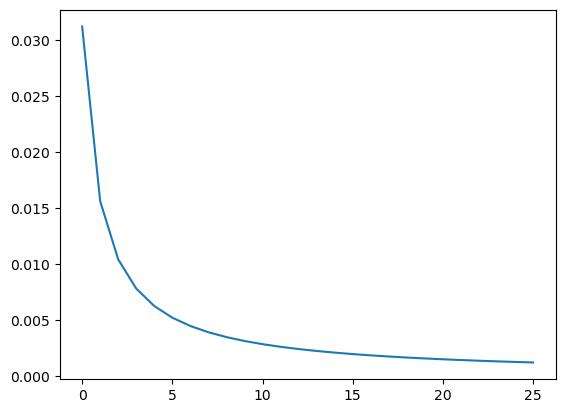

In [73]:
plt.plot(iter_info[32]["eff_lr"])

# Exact benchmark

In [206]:
def read_matrix_solutions_from_file(matrix_file):
    with open(matrix_file) as mf:
        n_rows, n_cols = mf.readline().strip().split(" ")
        n_rows  = int(n_rows)
        n_cols = int(n_cols)
    
        matrix = np.empty((n_rows, n_cols), dtype = float)
        
        # read a matrix
        for i in range(n_rows):
            row = mf.readline().strip()
            matrix[i, :] = (np.frombuffer(row.encode('ascii'), dtype = np.uint8) == ord(b'1'))
        #the \n
        mf.readline()

        solutions = mf.readlines()
        solutions = np.array([line.strip().split() for line in solutions], dtype = 'uint32')
    return matrix, solutions

In [201]:
BENCHMARK_MATRICES_FOLDER = Path("../results/benchmark_matrices/").resolve()

In [ ]:
#TODO add matrix size
#TODO add execution time

In [243]:
results = []

lrs = np.logspace(-3, 0, 10)
shs = np.arange(2, 101, 10)

for matrix_file in BENCHMARK_MATRICES_FOLDER.iterdir():
    matrix, solutions = read_matrix_solutions_from_file(matrix_file)
    
    missingness = df_matrix.isna().sum().sum()/df_matrix.size
    if missingness == 1: continue

    if len(solutions) == 0: continue
    
    area = solutions[0][0].bit_count() * solutions[0][1].bit_count()
    
    df_matrix = pd.DataFrame(matrix)
    df_matrix[df_matrix == 0] = np.nan
    
    best_submatrix_area = 0
    areas_ratio = 0
    
    for lr in lrs:
        for sh in shs:
            submatrix = adaptive_prune_to_complete(df_matrix, learning_rate=lr, shrink_coeff=sh, verbose = False)
            if submatrix is None: continue
            submatrix_area = submatrix.size
            if best_submatrix_area < submatrix_area:
                best_submatrix_area = submatrix_area
                areas_ratio = best_submatrix_area / area
            if submatrix_area == area:
                for solution in solutions:
                    row_mask = int(solution[0])
                    row_indices = pd.Index([i for i in range(row_mask.bit_length()) if row_mask & (1 << i)])
                    if row_indices.equals(submatrix.index):
                        col_mask = int(solution[1])
                        col_indices = pd.Index([i for i in range(col_mask.bit_length()) if col_mask & (1 << i)])
                        if (col_indices == submatrix.columns).all():
                            pass
    results.append({
        "file": matrix_file.name,
        "matrix_area": matrix.size,
        "missing": missingness,
        "optimal_area": area,
        "submatrix_area": area,
        "areas_ratio": areas_ratio,
    })

results = pd.DataFrame(results)

In [238]:
results = results.assign(opt_to_matrix=lambda x:x.optimal_area / x.matrix_area)
ratio_bins = np.arange(0, 1.1, 0.1)
results["ratio_bucket"] = pd.cut(results["opt_to_matrix"], bins=ratio_bins, include_lowest=True, right=False)
results_across_solution_to_matrix_ratio = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("ratio_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_solution_to_matrix_ratio

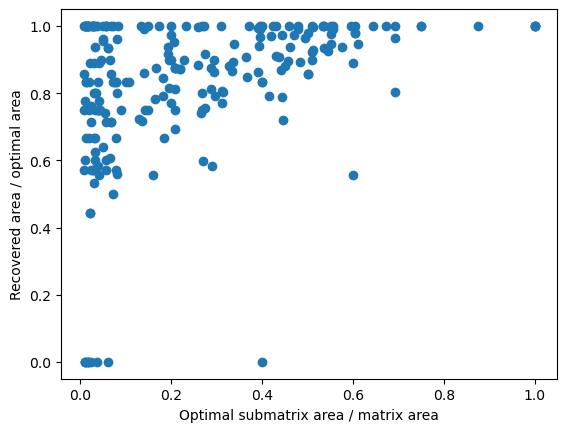

In [242]:
plt.scatter(
    results["optimal_area"] / results["matrix_area"],
    results["areas_ratio"]
)

plt.xlabel("Fraction of matrix area occupied by the optimal solution")
plt.ylabel("Recovered fraction of optimal area")
plt.show()

In [219]:
bins = np.arange(0, 1.1, 0.1)
results["missing_bucket"] = pd.cut(results["missing"], bins=bins, include_lowest = True, right = False)

In [222]:
results_across_missingness = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("missing_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_missingness

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
missing_bucket,,,,,
"[0.0, 0.1)",57,0.802655,0.875000,0.228070,0.438596
"[0.1, 0.2)",42,0.816150,0.888889,0.309524,0.452381
"[0.2, 0.3)",18,0.826761,0.870536,0.222222,0.444444
"[0.3, 0.4)",1,1.000000,1.000000,1.000000,1.000000
"[0.4, 0.5)",21,0.883952,0.946746,0.380952,0.619048
"[0.5, 0.6)",18,0.876317,0.899038,0.222222,0.500000
"[0.6, 0.7)",20,0.902649,0.927083,0.400000,0.600000
"[0.7, 0.8)",17,0.746206,0.833333,0.058824,0.352941
"[0.8, 0.9)",15,0.836862,0.897436,0.133333,0.400000


In [229]:
size_bins = np.arange(0, 900, 10)
size_bins
pd.cut(results["matrix_area"], bins=size_bins, include_lowest = True, right = False)

0      [500, 510)
1      [300, 310)
2      [300, 310)
3      [860, 870)
4      [300, 310)
          ...    
226    [300, 310)
227    [300, 310)
228    [300, 310)
229    [500, 510)
230    [500, 510)
Name: matrix_area, Length: 231, dtype: category
Categories (89, interval[int64, left]): [[0, 10) < [10, 20) < [20, 30) < [30, 40) ... [850, 860) < [860, 870) < [870, 880) < [880, 890)]

In [230]:
size_bins = np.arange(0, 900, 10)
results["size_bucket"] = pd.cut(results["matrix_area"], bins=size_bins, include_lowest = True, right = False)

In [231]:
results_across_size = (
    results
    .assign(recovered_90=results["areas_ratio"] >= 0.9)
    .groupby("size_bucket", observed=True)
    .agg(
        n=("areas_ratio", "size"),
        mean_recovery=("areas_ratio", "mean"),
        median_recovery=("areas_ratio", "median"),
        optimal_rate=("areas_ratio", lambda x: (x == 1).mean()),
        recovery_90_rate=("recovered_90", "mean"),
    )
)
results_across_size

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
size_bucket,,,,,
"[10, 20)",16,0.876736,1.000000,0.687500,0.687500
"[50, 60)",18,0.822584,0.895238,0.444444,0.500000
"[80, 90)",18,0.886070,0.989796,0.500000,0.722222
"[180, 190)",24,0.849703,0.958838,0.375000,0.541667
"[300, 310)",60,0.823434,0.884444,0.200000,0.466667
"[500, 510)",60,0.799397,0.870753,0.116667,0.400000
"[860, 870)",35,0.798224,0.800000,0.057143,0.228571


In [ ]:
#TODO results for optimal_area/matrix_size

,n,mean_recovery,median_recovery,optimal_rate,recovery_90_rate
missing_bucket,,,,,
"[0.0, 0.1)",57,0.802655,0.875000,0.228070,0.438596
"[0.1, 0.2)",42,0.816150,0.888889,0.309524,0.452381
"[0.2, 0.3)",18,0.826761,0.870536,0.222222,0.444444
"[0.3, 0.4)",1,1.000000,1.000000,1.000000,1.000000
"[0.4, 0.5)",21,0.883952,0.946746,0.380952,0.619048
"[0.5, 0.6)",18,0.876317,0.899038,0.222222,0.500000
"[0.6, 0.7)",20,0.902649,0.927083,0.400000,0.600000
"[0.7, 0.8)",17,0.746206,0.833333,0.058824,0.352941
"[0.8, 0.9)",15,0.836862,0.897436,0.133333,0.400000


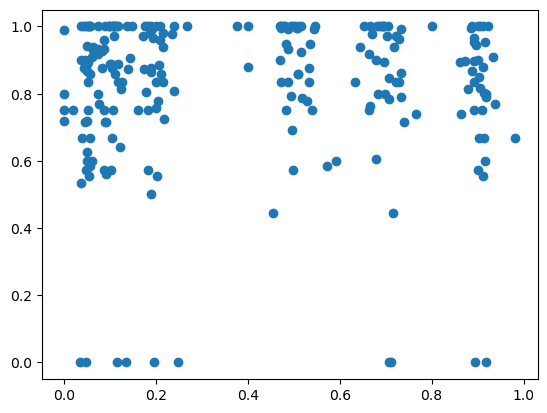

In [213]:
import matplotlib.pyplot as plt

plt.scatter(results["missing"], results["areas_ratio"])
plt.show()

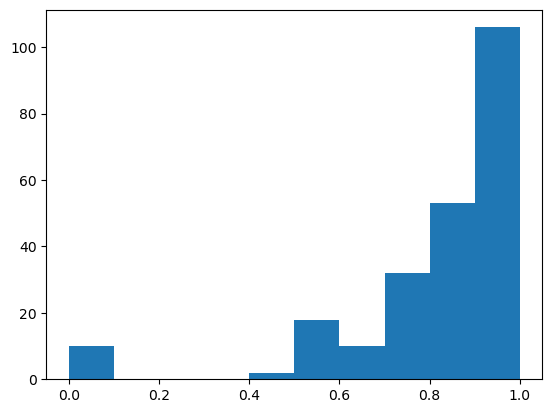

In [216]:
plt.hist(results["areas_ratio"])
plt.show()

In [215]:
missing_mask = ((results["missing"] >= 0) & (results["missing"] <= 0.5))
results_100_ratio_mask = results["areas_ratio"] == 1
results_90_ratio_mask = results["areas_ratio"] >= 0.9
print((missing_mask & results_100_ratio_mask).sum() / len(results[missing_mask]))
print((missing_mask & results_90_ratio_mask).sum() / len(results[missing_mask]))

0.2785714285714286
0.4714285714285714
